# Evidence Novelty

Repeated range observations are not necessarily independent. Observations acquired from similar sensor states may contain substantially redundant information and should therefore not increase evidence concentration at the same rate as observations acquired from novel states.

This example defines observation novelty using Mahalanobis distance in a lifted spatiotemporal acquisition space.

In [14]:
import matplotlib.pyplot as plt
import numpy as np

from beta_evidence_field import OccupancyField, OccupancyObservation

from tools.plotting import (configure_plots,
                            plot_field_2d,
                            plot_field_comparison_2d)

configure_plots()

field = OccupancyField.from_yaml("../config/example_2d_config.yaml")

In [15]:
def make_observation(origin    = np.array([0.0, 0.0]),
                     angle     = 0.0,
                     time      = 0.0,
                     wall      = 3.0):

    direction = np.array([np.cos(angle),
                          np.sin(angle)])

    return OccupancyObservation(origin    = np.asarray(origin, dtype = float),
                                direction = direction,
                                range     = (wall - origin[0])/direction[0],
                                returned  = True,
                                time      = time)

In [16]:
angles  = np.linspace(0.0, np.radians(60.0), 200)
novelty = []

for angle in angles:

    field.clear()

    field.add([
        make_observation(time = 0.0)
    ])

    observation = make_observation(
        angle = angle,
        time  = 0.1,
    )

    field.add([observation])

    novelty.append(observation.novelty)

novelty = np.asarray(novelty)

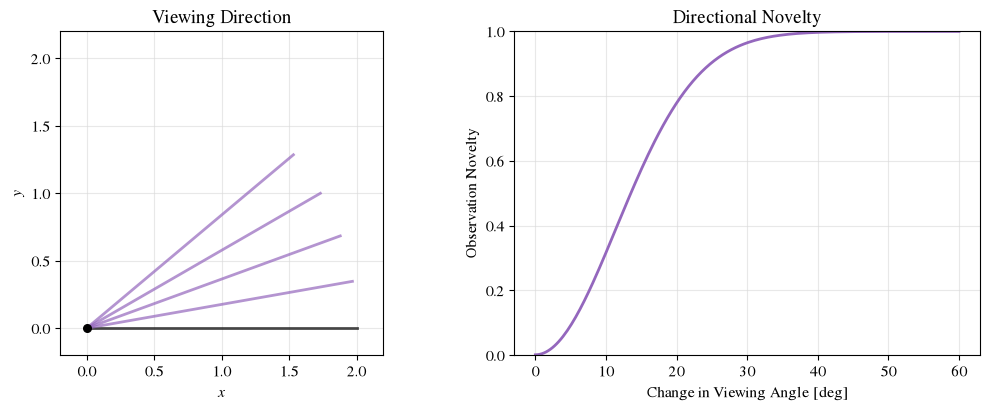

In [17]:
fig, axes = plt.subplots(1, 2,
                         figsize            = (10, 4),
                         constrained_layout = True)

example_angles = np.radians([0.0, 10.0, 20.0, 30.0, 40.0])

for angle in example_angles:

    direction = np.array([
        np.cos(angle),
        np.sin(angle),
    ])

    axes[0].plot([0.0, 2.0*direction[0]],
                 [0.0, 2.0*direction[1]],
                 color     = "tab:purple" if angle > 0.0 else "black",
                 linewidth = 2,
                 alpha     = 0.7)

axes[0].scatter(0.0,
                0.0,
                color  = "black",
                s      = 30,
                zorder = 3)

axes[0].set_xlim(-0.2, 2.2)
axes[0].set_ylim(-0.2, 2.2)
axes[0].set_aspect("equal")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].set_title("Viewing Direction")

axes[1].plot(np.degrees(angles),
             novelty,
             color     = "tab:purple",
             linewidth = 2)

axes[1].set_xlabel("Change in Viewing Angle [deg]")
axes[1].set_ylabel("Observation Novelty")
axes[1].set_ylim(0.0, 1.0)
axes[1].set_title("Directional Novelty")

for axis in axes:
    axis.grid(color = "0.85",
              alpha = 0.6)

In [18]:
displacement = np.linspace(0.0, 2.0, 200)
novelty      = []

for dy in displacement:

    field.clear()
    field.add([make_observation(time = 0.0)])

    observation = make_observation(origin = np.array([0.0, dy]),
                                   time   = 0.1)

    field.add([observation])
    novelty.append(observation.novelty)

novelty = np.asarray(novelty)

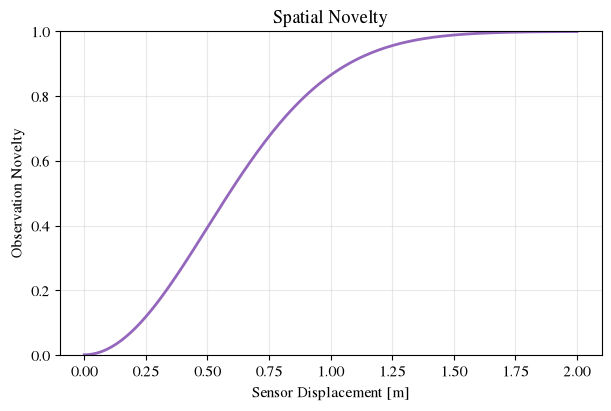

In [19]:
fig, axis = plt.subplots(figsize = (6, 4),
                         constrained_layout = True)

axis.plot(displacement,
          novelty,
          color     = "tab:purple",
          linewidth = 2)

axis.set_xlabel("Sensor Displacement [m]")
axis.set_ylabel("Observation Novelty")
axis.set_ylim(0.0, 1.0)
axis.set_title("Spatial Novelty")

axis.grid(color = "0.85",
          alpha = 0.6)

In [20]:
delta_time = np.linspace(0.001, 6.0, 200)
novelty    = []

for dt in delta_time:

    field.clear()

    field.add([
        make_observation(time = 0.0)
    ])

    observation = make_observation(
        time = dt
    )

    field.add([observation])

    novelty.append(observation.novelty)

novelty = np.asarray(novelty)

expected = 1.0 - np.exp(
    -0.5*delta_time**2/field.temporal_variance
)

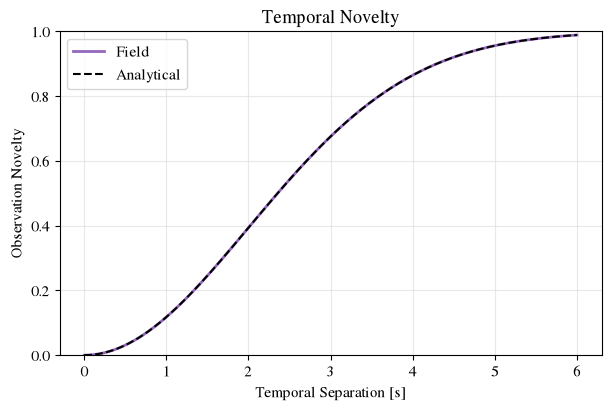

In [21]:
fig, axis = plt.subplots(figsize = (6, 4),
                         constrained_layout = True)

axis.plot(delta_time,
          novelty,
          color     = "tab:purple",
          linewidth = 2,
          label     = "Field")

axis.plot(delta_time,
          expected,
          color     = "black",
          linestyle = "--",
          linewidth = 1.5,
          label     = "Analytical")

axis.set_xlabel("Temporal Separation [s]")
axis.set_ylabel("Observation Novelty")
axis.set_ylim(0.0, 1.0)
axis.set_title("Temporal Novelty")

axis.grid(color = "0.85",
          alpha = 0.6)

axis.legend()

In [22]:
angles = np.linspace(-0.35, 0.35, 20)

observations = [
    make_observation(
        angle = angle,
        time  = 0.0,
    )

    for angle in angles
]

field.clear()
field.add(observations)

novelty = np.asarray([
    observation.novelty
    for observation in observations
])

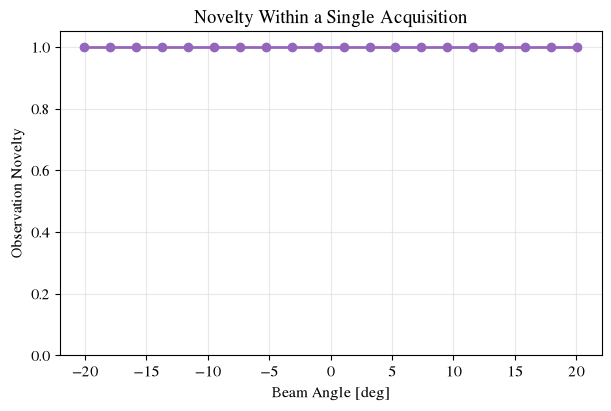

In [23]:
fig, axis = plt.subplots(figsize = (6, 4),
                         constrained_layout = True)

axis.plot(np.degrees(angles),
          novelty,
          color     = "tab:purple",
          marker    = "o",
          linewidth = 2)

axis.set_xlabel("Beam Angle [deg]")
axis.set_ylabel("Observation Novelty")
axis.set_ylim(0.0, 1.05)
axis.set_title("Novelty Within a Single Acquisition")

axis.grid(color = "0.85",
          alpha = 0.6)

In [ ]:
field.clear()

first_scan = [
    make_observation(
        angle = angle,
        time  = 0.0,
    )

    for angle in angles
]

second_scan = [
    make_observation(
        angle = angle,
        time  = 0.1,
    )

    for angle in angles
]

field.add(first_scan)
field.add(second_scan)

first_novelty = np.asarray([
    observation.novelty
    for observation in first_scan
])

second_novelty = np.asarray([
    observation.novelty
    for observation in second_scan
])

In [ ]:
fig, axis = plt.subplots(figsize = (6, 4),
                         constrained_layout = True)

axis.plot(np.degrees(angles),
          first_novelty,
          color     = "black",
          linewidth = 2,
          label     = "First acquisition")

axis.plot(np.degrees(angles),
          second_novelty,
          color     = "tab:purple",
          linewidth = 2,
          label     = "Repeated acquisition")

axis.set_xlabel("Beam Angle [deg]")
axis.set_ylabel("Observation Novelty")
axis.set_ylim(0.0, 1.05)
axis.set_title("Repeated Acquisition")

axis.grid(color = "0.85",
          alpha = 0.6)

axis.legend()